## importing Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pm4py
import importlib
importlib.reload(bn)
from bn import BottleneckAnalyzer



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




## Event Log Analysis

In [3]:
event = pd.read_csv('../data/p2p_event_log.csv')
event['Timestamp'] = pd.to_datetime(event.Timestamp)
event.columns = event.columns.str.lower()
event.head()

,case_id,activity,timestamp,vendor_id,approver_id,amount,exception_flag,approval_status,match_status
0,CASE000001,Create Requisition,2025-04-06 23:14:00.324787,VEN0076,APR011,23011.82,No,Approved,Matched
1,CASE000001,Clarification,2025-04-07 08:14:00.324787,VEN0076,APR011,23011.82,No,Approved,Matched
2,CASE000001,Approval,2025-04-08 01:14:00.324787,VEN0076,APR011,23011.82,No,Approved,Matched
3,CASE000001,Issue Purchase Order,2025-04-08 03:14:00.324787,VEN0076,APR011,23011.82,No,Approved,Matched
4,CASE000001,Goods Receipt,2025-04-20 03:14:00.324787,VEN0076,APR011,23011.82,No,Approved,Matched


In [11]:
event.info()

<class 'pandas.DataFrame'>
RangeIndex: 81041 entries, 0 to 81040
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Case ID          81041 non-null  str           
 1   Activity         81041 non-null  str           
 2   Timestamp        81041 non-null  datetime64[us]
 3   Vendor ID        81041 non-null  str           
 4   Approver ID      81041 non-null  str           
 5   Amount           81041 non-null  float64       
 6   Exception Flag   81041 non-null  str           
 7   Approval Status  81041 non-null  str           
 8   Match Status     81041 non-null  str           
dtypes: datetime64[us](1), float64(1), str(7)
memory usage: 5.6 MB


In [3]:
print(f'Total number of cases: {len(event["case_id"].unique())}')
print(f'Total number of events: {len(event)}')
print(f'Total number unique of activities: {len(event["activity"].unique())}')

Total number of cases: 10000
Total number of events: 81041
Total number unique of activities: 9


In [19]:
event = pm4py.format_dataframe(event,
                                case_id='case_id',
                                activity_key='activity',
                                timestamp_key='timestamp')
event_log = pm4py.convert_to_event_log(event)
event_log

[{'attributes': {'concept:name': 'CASE000001'}, 'events': [{'case_id': 'CASE000001', 'activity': 'Create Requisition', 'timestamp': Timestamp('2025-04-06 23:14:00.324787+0000', tz='UTC'), 'vendor_id': 'VEN0076', 'approver_id': Timestamp('1-04-11 00:00:00+0000', tz='UTC'), 'amount': 23011.82, 'exception_flag': 'No', 'approval_status': 'Approved', 'match_status': 'Matched', 'concept:name': 'Create Requisition', 'time:timestamp': Timestamp('2025-04-06 23:14:00.324787+0000', tz='UTC'), '@@index': 0, '@@case_index': 0}, '..', {'case_id': 'CASE000001', 'activity': 'Vendor Payment', 'timestamp': Timestamp('2025-05-02 03:14:00.324787+0000', tz='UTC'), 'vendor_id': 'VEN0076', 'approver_id': Timestamp('1-04-11 00:00:00+0000', tz='UTC'), 'amount': 23011.82, 'exception_flag': 'No', 'approval_status': 'Approved', 'match_status': 'Matched', 'concept:name': 'Vendor Payment', 'time:timestamp': Timestamp('2025-05-02 03:14:00.324787+0000', tz='UTC'), '@@index': 7, '@@case_index': 0}]}, '....', {'attribu

In [30]:
dfg, start_activities, end_activities = pm4py.discover_dfg(
    event,
    activity_key="activity",
    timestamp_key="timestamp",
    case_id_key="case_id",
)

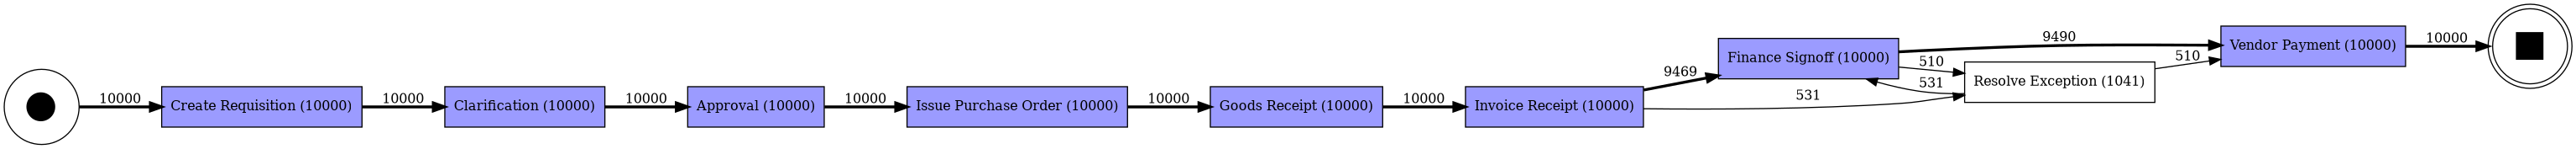

In [39]:
pm4py.view_dfg(dfg, start_activities, end_activities)

In [40]:
net_a, im_a, fm_a = pm4py.discover_petri_net_alpha(
    event,
        activity_key="activity",
        timestamp_key="timestamp",
        case_id_key="case_id",
)

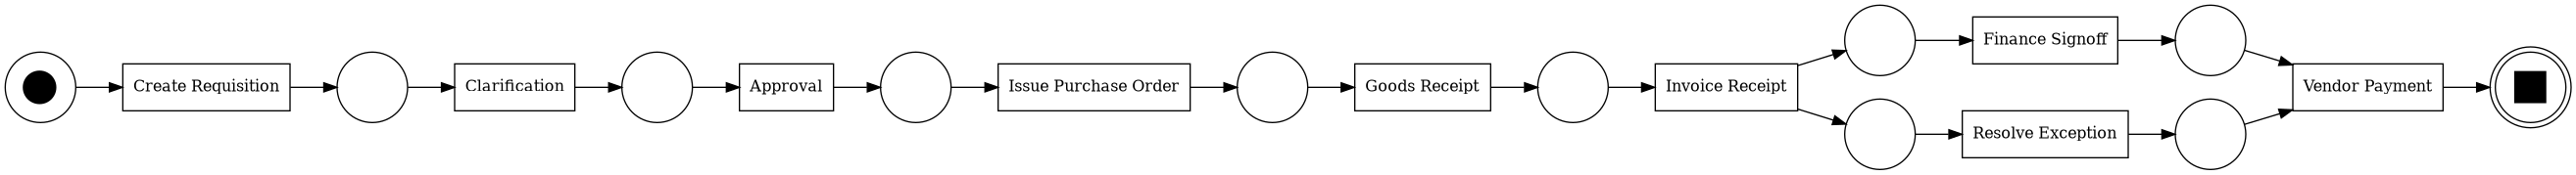

In [42]:
pm4py.view_petri_net(net_a, im_a, fm_a)

In [43]:
tree = pm4py.discover_process_tree_inductive(event,
                                       activity_key="activity",
                                         timestamp_key="timestamp",
                                           case_id_key="case_id")

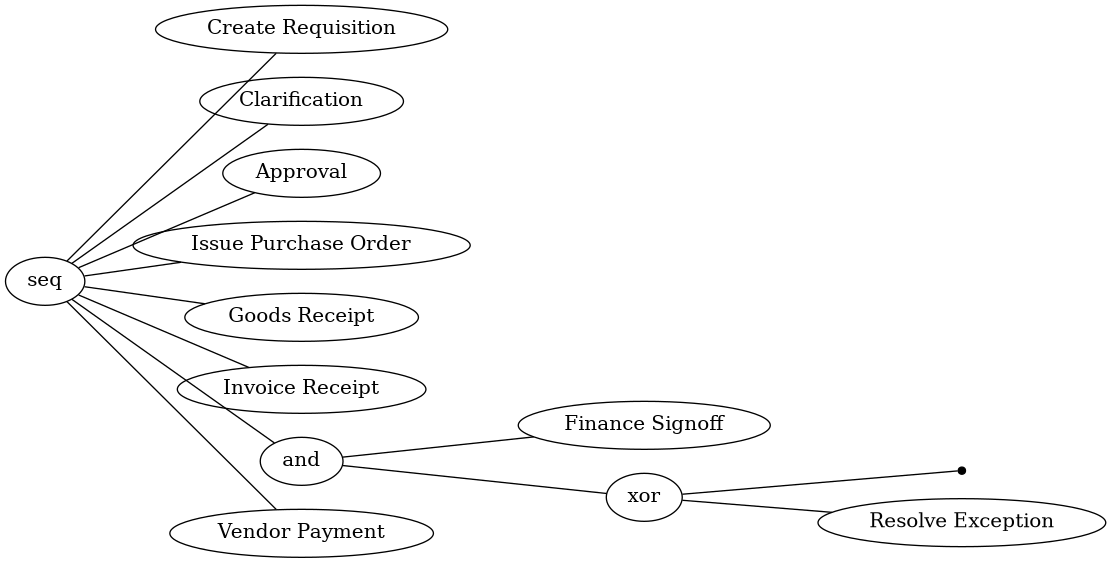

In [45]:
pm4py.view_process_tree(tree)

## Trasaction analysis


In [5]:
transaction_df = pd.read_csv('../data/p2p_transaction_table.csv', parse_dates= True)
transaction_df.columns = transaction_df.columns.str.lower()
transaction_df.head()

,case_id,req_id,clarification_timestamp,plan_id,contingency_flag,approval_status,approver_id,approval_timestamp,amount,po_id,...,invoice_id,billed_amount,invoice_timestamp,match_status,exception_flag,resolution_notes,approval_batch_id,signoff_timestamp,payment_id,disbursement_timestamp
0,CASE000001,REQ000001,2025-04-07 08:14:00.324787,PLAN000001,Yes,Approved,APR011,2025-04-08 01:14:00.324787,23011.82,PO000001,...,INV000001,23643.85,2025-04-21 03:14:00.324787,Matched,No,NaN,BATCH089,2025-04-24 03:14:00.324787,PAY000001,2025-05-02 03:14:00.324787
1,CASE000002,REQ000002,2026-07-22 11:34:55.814240,PLAN000002,Yes,Approved,APR013,2026-07-23 12:34:55.814240,6915.89,PO000002,...,INV000002,7089.53,2026-08-04 23:34:55.814240,Matched,No,NaN,BATCH049,2026-08-08 23:34:55.814240,PAY000002,2026-09-24 23:34:55.814240
2,CASE000003,REQ000003,2025-08-27 12:14:48.005318,PLAN000003,Yes,Approved,APR008,2025-08-28 12:14:48.005318,29876.01,PO000003,...,INV000003,29827.65,2025-09-24 23:14:48.005318,Matched,No,NaN,BATCH029,2025-09-25 23:14:48.005318,PAY000003,2025-11-07 23:14:48.005318
3,CASE000004,REQ000004,2025-07-29 06:01:55.214043,PLAN000004,No,Approved,APR016,2025-07-30 14:01:55.214043,46011.06,PO000004,...,INV000004,45712.41,2025-08-17 01:01:55.214043,Matched,No,NaN,BATCH020,2025-08-18 01:01:55.214043,PAY000004,2025-09-13 01:01:55.214043
4,CASE000005,REQ000005,2025-12-12 16:42:12.563786,PLAN000005,Yes,Approved,APR009,2025-12-13 14:42:12.563786,26616.86,PO000005,...,INV000005,25841.58,2025-12-31 00:42:12.563786,Matched,No,NaN,BATCH009,2026-01-04 00:42:12.563786,PAY000005,2026-01-29 00:42:12.563786


In [6]:
transaction_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 27 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   case_id                  10000 non-null  str    
 1   req_id                   10000 non-null  str    
 2   clarification_timestamp  10000 non-null  str    
 3   plan_id                  10000 non-null  str    
 4   contingency_flag         10000 non-null  str    
 5   approval_status          10000 non-null  str    
 6   approver_id              10000 non-null  str    
 7   approval_timestamp       10000 non-null  str    
 8   amount                   10000 non-null  float64
 9   po_id                    10000 non-null  str    
 10  vendor_id                10000 non-null  str    
 11  po_issue_timestamp       10000 non-null  str    
 12  shipment_id              10000 non-null  str    
 13  expected_arrival_date    10000 non-null  str    
 14  gr_id                    10000 non

In [7]:
# Null and distinct-value counts for each column
profile = pd.DataFrame({
    "null_count": transaction_df.isna().sum(),
    "unique_count": transaction_df.nunique(dropna=True),
})
display(profile)



,null_count,unique_count
case_id,0,10000
req_id,0,10000
clarification_timestamp,0,10000
plan_id,0,10000
contingency_flag,0,2
approval_status,0,2
approver_id,0,20
approval_timestamp,0,10000
amount,0,9983
po_id,0,10000


In [8]:
timestamp_cols = transaction_df.columns[
    transaction_df.columns.str.endswith("timestamp")
]
transaction_df[timestamp_cols] = transaction_df[timestamp_cols].apply(pd.to_datetime)

In [5]:
transaction_df.head()

,case_id,req_id,clarification_timestamp,plan_id,contingency_flag,approval_status,approver_id,approval_timestamp,amount,po_id,...,invoice_id,billed_amount,invoice_timestamp,match_status,exception_flag,resolution_notes,approval_batch_id,signoff_timestamp,payment_id,disbursement_timestamp
0,CASE000001,REQ000001,2025-04-07 08:14:00.324787,PLAN000001,Yes,Approved,APR011,2025-04-08 01:14:00.324787,23011.82,PO000001,...,INV000001,23643.85,2025-04-21 03:14:00.324787,Matched,No,NaN,BATCH089,2025-04-24 03:14:00.324787,PAY000001,2025-05-02 03:14:00.324787
1,CASE000002,REQ000002,2026-07-22 11:34:55.814240,PLAN000002,Yes,Approved,APR013,2026-07-23 12:34:55.814240,6915.89,PO000002,...,INV000002,7089.53,2026-08-04 23:34:55.814240,Matched,No,NaN,BATCH049,2026-08-08 23:34:55.814240,PAY000002,2026-09-24 23:34:55.814240
2,CASE000003,REQ000003,2025-08-27 12:14:48.005318,PLAN000003,Yes,Approved,APR008,2025-08-28 12:14:48.005318,29876.01,PO000003,...,INV000003,29827.65,2025-09-24 23:14:48.005318,Matched,No,NaN,BATCH029,2025-09-25 23:14:48.005318,PAY000003,2025-11-07 23:14:48.005318
3,CASE000004,REQ000004,2025-07-29 06:01:55.214043,PLAN000004,No,Approved,APR016,2025-07-30 14:01:55.214043,46011.06,PO000004,...,INV000004,45712.41,2025-08-17 01:01:55.214043,Matched,No,NaN,BATCH020,2025-08-18 01:01:55.214043,PAY000004,2025-09-13 01:01:55.214043
4,CASE000005,REQ000005,2025-12-12 16:42:12.563786,PLAN000005,Yes,Approved,APR009,2025-12-13 14:42:12.563786,26616.86,PO000005,...,INV000005,25841.58,2025-12-31 00:42:12.563786,Matched,No,NaN,BATCH009,2026-01-04 00:42:12.563786,PAY000005,2026-01-29 00:42:12.563786


In [99]:
bn_analyser = BottleneckAnalyzer(transaction_df)

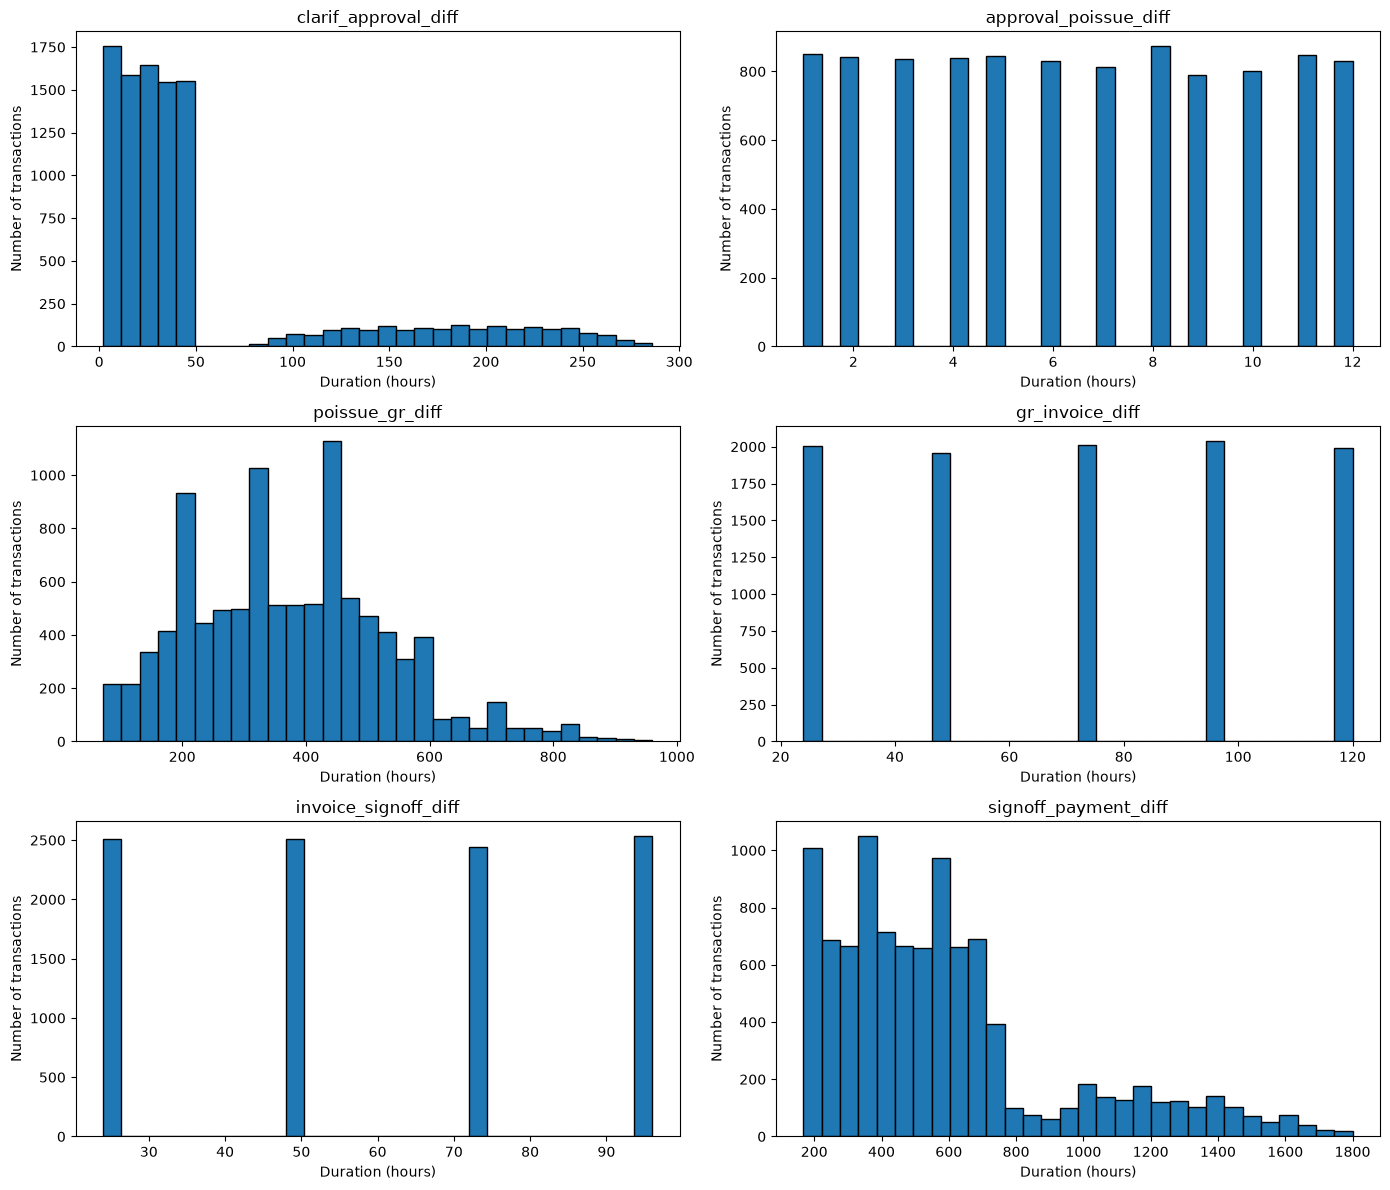

In [96]:
bn_analyser.timetaken_distribution()

In [104]:
sla = {'clarif_approval_diff': 48,  # 2 days
        'approval_poissue_diff': 12,  # 2 hours
        'poissue_gr_diff': 600, # 25 days
        'gr_invoice_diff': 120, # 5 days
        'invoice_signoff_diff': 72, # 3 days
        'signoff_payment_diff': 720} # 30 days

In [105]:
map, bn_case_ids = bn_analyser.identify_bottlenecks(sla)

In [ ]:
# in time processing, we can use the bottleneck map to identify the bottleneck activities and their corresponding case IDs.
#  This will help us understand where the delays are occurring in the process and which cases are affected by these delays.
print(map)


        Total_cases(10000)
          |
          ↓
        Clarification Requirements
          |
        8084 ie. (80.84%)
          ↓
        PR Approval
          |
        10000 ie. (100.00%)
          ↓
        PO Issue
          |
        9371 ie. (93.71%)
          ↓
        Goods Receipt
          |
        10000 ie. (100.00%)
          ↓
        Invoice
          |
        7468 ie. (74.68%)
          ↓
        Sign-off
          |
        8140 ie. (81.40%)
          ↓
        Payment


In [ ]:
transaction_df.set_index('case_id').loc[
    bn_case_ids['clarif_approval']
]

,req_id,clarification_timestamp,plan_id,contingency_flag,approval_status,approver_id,approval_timestamp,amount,po_id,vendor_id,...,invoice_id,billed_amount,invoice_timestamp,match_status,exception_flag,resolution_notes,approval_batch_id,signoff_timestamp,payment_id,disbursement_timestamp
case_id,,,,,,,,,,,,,,,,,,,,,
CASE000025,REQ000025,2025-12-11 16:56:13.484299,PLAN000025,No,Approved,APR002,2025-12-19 08:56:13.484299,42195.20,PO000025,VEN0052,...,INV000025,41722.65,2025-12-25 09:56:13.484299,Matched,No,NaN,BATCH059,2025-12-29 09:56:13.484299,PAY000025,2026-01-09 09:56:13.484299
CASE000031,REQ000031,2026-02-07 09:45:44.400417,PLAN000031,Yes,Approved,APR006,2026-02-18 15:45:44.400417,4330.53,PO000031,VEN0099,...,INV000031,4352.19,2026-03-01 03:45:44.400417,Matched,No,NaN,BATCH028,2026-03-04 03:45:44.400417,PAY000031,2026-04-30 03:45:44.400417
CASE000037,REQ000037,2025-02-07 19:29:45.130853,PLAN000037,No,Approved,APR005,2025-02-13 04:29:45.130853,8827.91,PO000037,VEN0063,...,INV000037,8966.90,2025-03-01 15:29:45.130853,Matched,No,NaN,BATCH053,2025-03-05 15:29:45.130853,PAY000037,2025-03-27 15:29:45.130853
CASE000041,REQ000041,2026-09-29 17:15:16.204894,PLAN000041,Yes,Approved,APR014,2026-10-07 22:15:16.204894,35080.23,PO000041,VEN0095,...,INV000041,34224.65,2026-10-30 01:15:16.204894,Matched,No,NaN,BATCH078,2026-11-02 01:15:16.204894,PAY000041,2026-11-16 01:15:16.204894
CASE000043,REQ000043,2025-10-18 13:30:36.099398,PLAN000043,Yes,Rejected,APR017,2025-10-26 09:30:36.099398,11202.95,PO000043,VEN0039,...,INV000043,10941.29,2025-11-19 11:30:36.099398,Matched,No,NaN,BATCH019,2025-11-22 11:30:36.099398,PAY000043,2026-01-24 11:30:36.099398
CASE000044,REQ000044,2026-09-10 03:17:28.909265,PLAN000044,Yes,Approved,APR007,2026-09-18 11:17:28.909265,29374.69,PO000044,VEN0038,...,INV000044,29221.43,2026-10-09 15:17:28.909265,Matched,No,NaN,BATCH048,2026-10-12 15:17:28.909265,PAY000044,2026-11-09 15:17:28.909265
CASE000047,REQ000047,2025-12-23 21:07:09.148397,PLAN000047,No,Rejected,APR007,2026-01-01 21:07:09.148397,53159.73,PO000047,VEN0069,...,INV000047,53777.67,2026-01-16 22:07:09.148397,Matched,No,NaN,BATCH027,2026-01-18 22:07:09.148397,PAY000047,2026-02-17 22:07:09.148397
CASE000048,REQ000048,2026-06-20 00:48:44.609368,PLAN000048,Yes,Approved,APR016,2026-06-29 17:48:44.609368,8867.55,PO000048,VEN0050,...,INV000048,9100.48,2026-07-23 21:48:44.609368,Matched,No,NaN,BATCH064,2026-07-26 21:48:44.609368,PAY000048,2026-08-18 21:48:44.609368
CASE000049,REQ000049,2024-11-03 22:01:52.934239,PLAN000049,Yes,Approved,APR001,2024-11-10 13:01:52.934239,20693.81,PO000049,VEN0074,...,INV000049,21193.45,2024-12-02 15:01:52.934239,Matched,No,NaN,BATCH085,2024-12-06 15:01:52.934239,PAY000049,2024-12-19 15:01:52.934239
